# Reproducible CPP spectral-feature example

This example uses the complete official **MLCPP 2.0 Layer1** website downloads,
corrected Protspect features, and a pinned MISTIC source. It does not reproduce
the historical exploration or claim a new independent biological benchmark.

Source studies: [MLCPP (2018)](https://doi.org/10.1021/acs.jproteome.8b00148)
and [MLCPP 2.0 (2022)](https://doi.org/10.1016/j.jmb.2022.167604).
Data: [official downloads](https://balalab-skku.org/mlcpp2/download/).
The pinned snapshot contains 1,146 training records and 2,341 test records.
Four exact training duplicates are excluded from test evaluation, retaining
2,337 test records (153 positive and 2,184 negative). Official FASTA identifiers,
record order, source URLs and hashes are preserved. No historical subset is used.
Related peptide families may still cross splits.

Prepare the website data and pinned environment using `research/README.md`.
A fresh run output directory is required.

In [1]:
from pathlib import Path
import os
import json
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'research/cpp_workflow.py').exists())
os.chdir(ROOT)
from research.cpp_workflow import run
from research.plot_cpp import plot_results

OUTPUT = Path(os.environ.get('PROTSPECT_CPP_OUTPUT', 'validation/cpp_official_run'))
TRAIN = ROOT / 'research/data/mlcpp2/training.csv'
TEST = ROOT / 'research/data/mlcpp2/independent.csv'


## Fixed protocol

Seed 7; FFT length 64; BLOSUM100 amplitudes; raw scaling and no channel centering.
The scaler fits only the 80% training-fit subset during selection. The remaining
20% of the **training file** selects RBF settings and the MISTIC ranking weight.
Final preprocessing and selected algorithms refit on all training rows.
No test outcomes select settings. MISTIC's internal scores are search heuristics,
not independent validation estimates. Its internal member splits, ranking and
feature-removal search are seeded and recorded. Both algorithms are evaluated
as predeclared examples; no test-based winner selection is performed.

In [2]:
report = run(TRAIN, TEST, OUTPUT, with_mistic=True)
print('Training rows:', report['data']['train']['rows'])
print('Test rows retained:', report['data']['test_exact_disjoint']['rows'])
print('Exact duplicate test rows excluded:', len(report['data']['test_exact_disjoint']['excluded_exact_duplicates']))
print('MISTIC source commit:', report['source']['mistic']['commit'])


Training rows: 1146
Test rows retained: 2337
Exact duplicate test rows excluded: 4
MISTIC source commit: 8f115591921ed9b14fa03716246898694753780e


In [3]:
summary = pd.DataFrame({name: model['test'] for name, model in report['models'].items()}).T
summary[['balanced_accuracy', 'mcc', 'f1', 'roc_auc', 'average_precision', 'sensitivity', 'specificity']].round(4)


,balanced_accuracy,mcc,f1,roc_auc,average_precision,sensitivity,specificity
rbf_svc,0.857798,0.481218,0.479245,0.915069,0.691771,0.830065,0.885531
mistic,0.777733,0.295153,0.286034,0.871316,0.494723,0.836601,0.718864


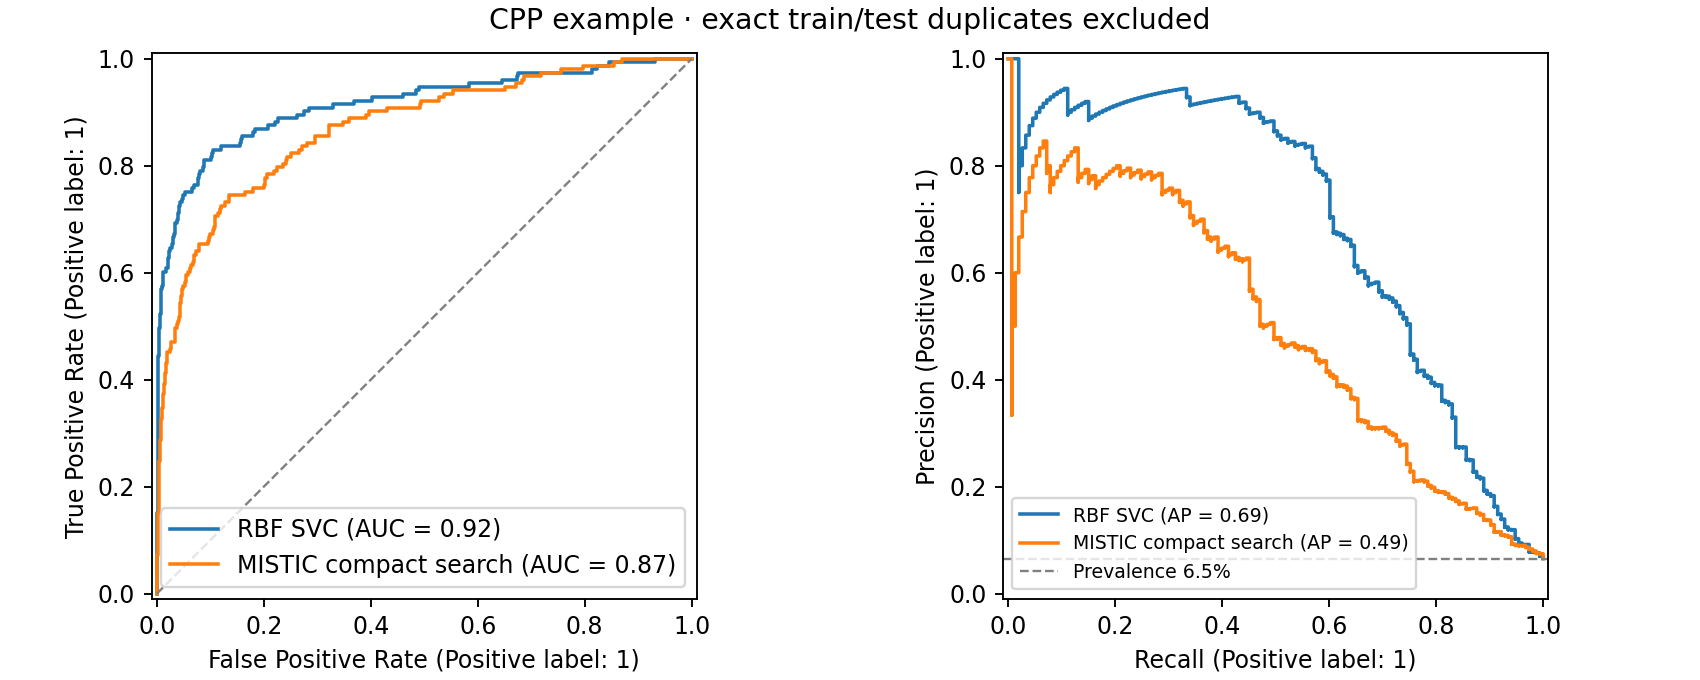

In [4]:
plot_results(OUTPUT)
display(Image(filename=str(OUTPUT / 'evaluation.png')))


## A small feature-space explanation

The attribution sample contains 32 deterministic test rows, chosen without labels
and used only after settings are fixed. Integrated gradients explain the MISTIC
member-ensemble decision in **standardized spectral-feature space**, relative to
the zero vector (training feature means). This is not residue attribution,
a causal explanation, or evidence of a binding mechanism. No explanation result
feeds back into model selection.

Selected rank weight: 0.5
Selected features: 35


,feature,mean_absolute_integrated_gradient
0,Amp_R_0.0,0.2857
1,Amp_K_0.0,0.1953
2,Amp_D_0.03125,0.1816
3,Amp_V_0.25,0.1619
4,Amp_R_0.015625,0.1319
5,Amp_R_0.25,0.1174
6,Amp_V_0.0,0.1166
7,Amp_R_0.0625,0.1162
8,Amp_H_0.03125,0.0966
9,Amp_P_0.0,0.0947


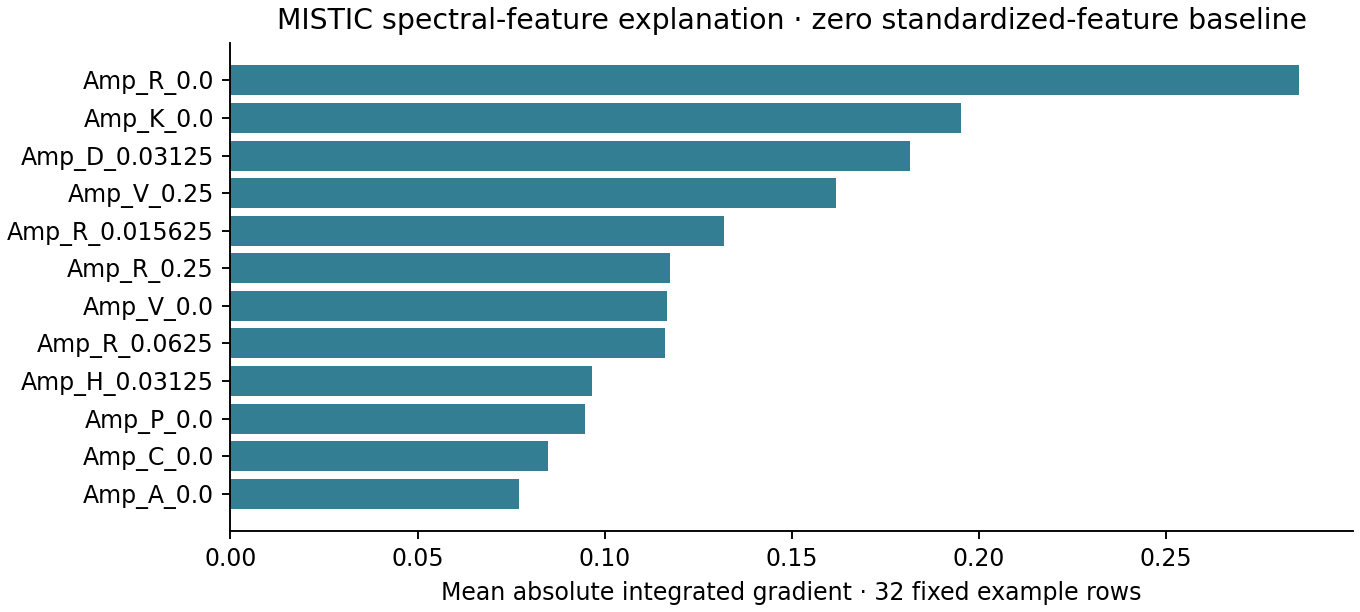

In [5]:
print('Selected rank weight:', report['models']['mistic']['selected_rank_weight'])
print('Selected features:', len(report['models']['mistic']['selected_features']))
display(pd.read_csv(OUTPUT / 'attribution_summary.csv').round(4))
display(Image(filename=str(OUTPUT / 'attributions.png')))


## What to preserve and what remains uncertain

The run stores download and prepared-file hashes, official source identifiers,
original-row split manifests, excluded and retained test row IDs, all validation
trials, ordered feature metadata, selected features/settings, warnings,
predictions and attribution rows. Unavailable probability-calibration statistics
are recorded as null because these SVCs use decision values with
`probability=False`.

This example uses the complete official downloads; no historical subsetting rule
is needed. The four training overlaps are explicitly excluded, so this is not
an identical copy of the paper's test evaluation. Raw downloads and prepared
CSVs are local cache files, excluded from package distributions. No raw peptide
sequences are copied into reports. The task is Layer1 CPP classification, not
Layer2 uptake-efficiency prediction.

Repeated runs in the same pinned environment should produce identical settings
and class predictions and numerically matching decision scores. Versions and
source hashes are recorded; cross-platform bitwise equivalence is not promised.

In [6]:
assert not report['warnings'], report['warnings']
print('Run artifacts:', OUTPUT.name)
print('All model test metrics and feature metadata saved.')


Run artifacts: cpp_official_run
All model test metrics and feature metadata saved.
